# НИРМ3 — неделя 7: базовая 1D-CNN, гиперпараметры и устойчивость к seed

Обучение выполнено на GPU в `nirm3_week7-8_colab_training.ipynb` (Google Colab, Tesla T4); здесь —
анализ сохранённых предсказаний (`cache/results/`). Протокол оценки — недели 4: выбор эпохи и
конфигурации по фолду 9, тестовый фолд 10 в выборе не участвует.

Задачи недели 7:
1. Воспроизведение ResNet1d недели 5 на GPU — все глубокие модели теперь сравниваются в одной среде.
2. Базовая (простая) 1D-CNN против ResNet1d.
3. Подбор гиперпараметров ResNet1d: длина окна × ширина сети × learning rate (8 конфигураций).
4. Устойчивость к seed: 3 запуска лучшей конфигурации — разброс качества и разрыва по полу.

In [1]:
import glob
import json
import os

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.stats import rankdata
from sklearn.metrics import roc_auc_score

SEED = 42
CACHE = 'cache' + os.sep
FIG_DIR = CACHE + 'fig' + os.sep
RESULTS = CACHE + 'results' + os.sep
assert glob.glob(RESULTS + '*.json'), 'скачайте results/ из Google Drive (см. ноутбук Colab)'
plt.rcParams.update({'font.size': 9, 'axes.grid': True, 'grid.alpha': 0.3})
SEX_COLORS = {'male': '#4C72B0', 'female': '#C44E52'}
SUPERCLASSES = ['NORM', 'MI', 'STTC', 'CD', 'HYP']

meta = np.load(CACHE + 'colab_meta.npz')
Y, split, has_label, sex = meta['Y'].astype(int), meta['split'], meta['has_label'], meta['sex']
va, te = [np.where((split == s) & has_label)[0] for s in ('val', 'test')]
y_va, y_te, sex_va, sex_te = Y[va], Y[te], sex[va], sex[te]

RUNS = {}
for f in sorted(glob.glob(RESULTS + '*.json')):
    info = json.load(open(f))
    z = np.load(f.replace('.json', '.npz'))
    assert np.array_equal(z['val_idx'], va) and np.array_equal(z['test_idx'], te)
    RUNS[info['run_id']] = {**info, 's_val': z['s_val'], 's_test': z['s_test']}
print(f'прогонов: {len(RUNS)}; среда: {next(iter(RUNS.values()))["env"]}')

прогонов: 19; среда: {'torch': '2.11.0+cu130', 'cuda': '13.0', 'device': 'cuda', 'gpu': 'Tesla T4'}


## Протокол оценки

Функции недели 4–5; AUC считается через ранги сразу по всем классам (результат совпадает с
`roc_auc_score`, проверка ниже) — так бутстреп по нескольким seed идёт за секунды.

In [2]:
N_BOOT = 1000
TARGET_SENS = 0.90


def auc_per_class(y, s):
    r = rankdata(s, axis=0)
    n_pos = y.sum(axis=0)
    n_neg = len(y) - n_pos
    return ((r * y).sum(axis=0) - n_pos * (n_pos + 1) / 2) / (n_pos * n_neg)


def macro_auc(y, s):
    return auc_per_class(y, s).mean()


def screening_thresholds(y_val, s_val, target=TARGET_SENS):
    th = []
    for k in range(y_val.shape[1]):
        pos_scores = np.sort(s_val[y_val[:, k] == 1, k])
        th.append(pos_scores[int(np.floor((1 - target) * len(pos_scores)))])
    return np.array(th)


def seed_mean_ci(y, scores, metric, n=N_BOOT, seed=SEED):
    """Метрика, усреднённая по seed: точка и 95 % бутстреп-интервал по записям."""
    rng = np.random.default_rng(seed)
    point = np.mean([metric(y, s) for s in scores], axis=0)
    boots = []
    for _ in range(n):
        idx = rng.integers(0, len(y), len(y))
        boots.append(np.mean([metric(y[idx], s[idx]) for s in scores], axis=0))
    return point, np.percentile(boots, [2.5, 97.5], axis=0)


def paired_diff(y, scores_a, scores_b, n=N_BOOT, seed=SEED):
    """Разность macro-AUC (усреднённого по seed) двух моделей на одних и тех же бутстреп-выборках."""
    rng = np.random.default_rng(seed)
    point = np.mean([macro_auc(y, s) for s in scores_a]) - np.mean([macro_auc(y, s) for s in scores_b])
    diffs = []
    for _ in range(n):
        idx = rng.integers(0, len(y), len(y))
        diffs.append(np.mean([macro_auc(y[idx], s[idx]) for s in scores_a])
                     - np.mean([macro_auc(y[idx], s[idx]) for s in scores_b]))
    return point, *np.percentile(diffs, [2.5, 97.5])


def sex_gap_ci(y, scores, sx, n=N_BOOT, seed=SEED):
    """AUC женщины − мужчины по классам и macro, усреднение по seed, бутстреп внутри каждого пола."""
    rng = np.random.default_rng(seed)
    f_idx, m_idx = np.where(sx == 'female')[0], np.where(sx == 'male')[0]

    def gap(fi, mi):
        g = np.mean([auc_per_class(y[fi], s[fi]) - auc_per_class(y[mi], s[mi]) for s in scores], axis=0)
        return np.append(g, g.mean())

    point = gap(f_idx, m_idx)
    boots = [gap(rng.choice(f_idx, len(f_idx)), rng.choice(m_idx, len(m_idx))) for _ in range(n)]
    lo, hi = np.percentile(boots, [2.5, 97.5], axis=0)
    return pd.DataFrame({'female - male': point, 'CI low': lo, 'CI high': hi}, index=SUPERCLASSES + ['macro'])


def scores_of(*run_ids, part='s_test'):
    return [RUNS[r][part] for r in run_ids]


s0 = RUNS['resnet1d_w2.5_c64-128-128_lr0.001_s42']['s_test']
assert np.allclose(auc_per_class(y_te, s0), [roc_auc_score(y_te[:, k], s0[:, k]) for k in range(5)])

## Задача 1. Воспроизведение ResNet1d на GPU

Та же архитектура, гиперпараметры и seed, что на неделе 5 (CPU). Полного совпадения не ожидается:
порядок операций свёрток на GPU и CPU разный, поэтому веса расходятся с первых шагов.

In [3]:
REF = 'resnet1d_w2.5_c64-128-128_lr0.001_s42'
w5 = np.load(CACHE + 'resnet1d_scores.npz')
repro = pd.DataFrame({
    'CPU (week 5)': [0.9331, 20, macro_auc(y_te, w5['s_test'])],
    'GPU (week 7)': [RUNS[REF]['val_macro_auc'], RUNS[REF]['best_epoch'], macro_auc(y_te, RUNS[REF]['s_test'])],
}, index=['val macro-AUC', 'best epoch', 'test macro-AUC'])
print(repro.round(4).to_string())
d, lo, hi = paired_diff(y_te, [RUNS[REF]['s_test']], [w5['s_test']])
print(f'\nGPU − CPU, test macro-AUC: {d:+.4f} [{lo:+.4f}; {hi:+.4f}]')
print(f'корреляция предсказаний на тесте: {np.corrcoef(RUNS[REF]["s_test"].ravel(), w5["s_test"].ravel())[0, 1]:.3f}')
print(f'время обучения: CPU 38.9 мин, GPU {RUNS[REF]["train_minutes"]:.1f} мин')

                CPU (week 5)  GPU (week 7)
val macro-AUC         0.9331        0.9327
best epoch           20.0000       17.0000
test macro-AUC        0.9297        0.9295



GPU − CPU, test macro-AUC: -0.0001 [-0.0016; +0.0012]
корреляция предсказаний на тесте: 0.990
время обучения: CPU 38.9 мин, GPU 3.2 мин


## Задача 2. Базовая 1D-CNN

Четыре блока «свёртка 7 → свёртка 7 → max-pooling» (32 → 64 → 128 → 128 каналов), глобальный
average + max pooling, 457 тыс. параметров — без остаточных связей. Остальное обучение — как у ResNet1d.

In [4]:
CNN = 'cnn_w2.5_c32-64-128-128_lr0.001_s42'
rows = []
for name, rid in (('ResNet1d', REF), ('plain 1D-CNN', CNN)):
    r = RUNS[rid]
    rows.append({'model': name, 'params': r['n_params'], 'train_min': round(r['train_minutes'], 1),
                 'best_epoch': r['best_epoch'], 'val macro-AUC': r['val_macro_auc'],
                 'test macro-AUC': macro_auc(y_te, r['s_test']),
                 **dict(zip(SUPERCLASSES, auc_per_class(y_te, r['s_test'])))})
baseline_cmp = pd.DataFrame(rows).set_index('model')
print(baseline_cmp.round(3).to_string())
d, lo, hi = paired_diff(y_te, [RUNS[CNN]['s_test']], [RUNS[REF]['s_test']])
print(f'\nplain CNN − ResNet1d, test macro-AUC: {d:+.4f} [{lo:+.4f}; {hi:+.4f}]')

              params  train_min  best_epoch  val macro-AUC  test macro-AUC   NORM     MI   STTC     CD    HYP
model                                                                                                        
ResNet1d      510469        3.2          17          0.933           0.930  0.949  0.933  0.940  0.923  0.902
plain 1D-CNN  456965        0.7          17          0.934           0.932  0.949  0.931  0.942  0.926  0.911



plain CNN − ResNet1d, test macro-AUC: +0.0024 [-0.0007; +0.0051]


## Задача 3. Подбор гиперпараметров ResNet1d

Сетка 2 × 2 × 2: окно 2.5 / 5 с, ширина 64-128-128 / 128-256-256, learning rate 1e-3 / 3e-3; seed 42,
выбор по macro-AUC на фолде 9. На тесте оценивается только выбранная конфигурация.

In [5]:
grid_rows = []
for rid, r in RUNS.items():
    c = r['config']
    if c['model'] == 'resnet1d' and c['seed'] == 42:
        grid_rows.append({'window_s': c['win_s'], 'widths': '-'.join(map(str, c['widths'])), 'lr': c['lr'],
                          'params': r['n_params'], 'train_min': round(r['train_minutes'], 1),
                          'best_epoch': r['best_epoch'], 'val macro-AUC': r['val_macro_auc'],
                          'run_id': rid})
grid = pd.DataFrame(grid_rows).sort_values('val macro-AUC', ascending=False).reset_index(drop=True)
print(grid.drop(columns='run_id').round(4).to_string())
BEST = grid.run_id[0]
print(f'\nвыбрана: {BEST}; размах val macro-AUC по сетке: '
      f'{grid["val macro-AUC"].max() - grid["val macro-AUC"].min():.4f}')

effects = {
    'window 5 s vs 2.5 s': grid.groupby('window_s')['val macro-AUC'].mean().diff().iloc[-1],
    'wide vs narrow': grid.groupby('widths')['val macro-AUC'].mean()
    .pipe(lambda s: s['128-256-256'] - s['64-128-128']),
    'lr 3e-3 vs 1e-3': grid.groupby('lr')['val macro-AUC'].mean().diff().iloc[-1],
}
print('\nсредний эффект фактора на val macro-AUC: ' + ', '.join(f'{k} {v:+.4f}' for k, v in effects.items()))

   window_s       widths     lr   params  train_min  best_epoch  val macro-AUC
0       5.0  128-256-256  0.003  2020357       13.8          17         0.9357
1       2.5  128-256-256  0.003  2020357        8.1          18         0.9357
2       2.5  128-256-256  0.001  2020357        8.1          17         0.9355
3       5.0  128-256-256  0.001  2020357       13.8          17         0.9347
4       2.5   64-128-128  0.003   510469        3.3          20         0.9340
5       5.0   64-128-128  0.003   510469        5.4          20         0.9340
6       2.5   64-128-128  0.001   510469        3.2          17         0.9327
7       5.0   64-128-128  0.001   510469        5.4          17         0.9315

выбрана: resnet1d_w5.0_c128-256-256_lr0.003_s42; размах val macro-AUC по сетке: 0.0041

средний эффект фактора на val macro-AUC: window 5 s vs 2.5 s -0.0005, wide vs narrow +0.0023, lr 3e-3 vs 1e-3 +0.0013


## Задача 4. Устойчивость к seed

Лучшая конфигурация обучена с seed 42, 1, 2. Для каждого запуска — качество на тесте и разрыв по полу;
затем показатели, усреднённые по трём seed, с бутстреп-интервалом по тестовым записям.

In [6]:
best_cfg = RUNS[BEST]['config']
SEED_RUNS = sorted(r for r, v in RUNS.items()
                   if {**v['config'], 'seed': 0} == {**best_cfg, 'seed': 0})
k_mi = SUPERCLASSES.index('MI')
rows = []
for rid in SEED_RUNS:
    r = RUNS[rid]
    s = r['s_test']
    th = screening_thresholds(y_va, r['s_val'])
    f, m = sex_te == 'female', sex_te == 'male'
    sens = {g: (s[mask & (y_te[:, k_mi] == 1), k_mi] >= th[k_mi]).mean() for g, mask in (('f', f), ('m', m))}
    rows.append({'seed': r['config']['seed'], 'val macro-AUC': r['val_macro_auc'],
                 'test macro-AUC': macro_auc(y_te, s),
                 'macro gap F-M': macro_auc(y_te[f], s[f]) - macro_auc(y_te[m], s[m]),
                 'MI AUC gap F-M': auc_per_class(y_te[f], s[f])[k_mi] - auc_per_class(y_te[m], s[m])[k_mi],
                 'MI sens female': sens['f'], 'MI sens male': sens['m']})
seeds = pd.DataFrame(rows).set_index('seed')
seeds.loc['mean'] = seeds.mean()
seeds.loc['sd'] = seeds.iloc[:-1].std()
print(seeds.round(4).to_string())

scores_best = scores_of(*SEED_RUNS)
point, ci = seed_mean_ci(y_te, scores_best, macro_auc)
print(f'\ntest macro-AUC, среднее по 3 seed: {point:.3f} [{ci[0]:.3f}; {ci[1]:.3f}]')
d, lo, hi = paired_diff(y_te, scores_best, [RUNS[REF]['s_test']])
print(f'лучшая конфигурация (3 seed) − ResNet1d недели 5 (GPU): {d:+.4f} [{lo:+.4f}; {hi:+.4f}]')

gap_best = sex_gap_ci(y_te, scores_best, sex_te)
print('\nразрыв AUC женщины − мужчины, среднее по 3 seed:')
print(gap_best.round(3).to_string())

      val macro-AUC  test macro-AUC  macro gap F-M  MI AUC gap F-M  MI sens female  MI sens male
seed                                                                                            
1            0.9338          0.9311        -0.0218         -0.0286          0.8656        0.9226
2            0.9340          0.9295        -0.0226         -0.0308          0.8577        0.9192
42           0.9357          0.9286        -0.0241         -0.0380          0.8498        0.9226
mean         0.9345          0.9297        -0.0229         -0.0324          0.8577        0.9214
sd           0.0010          0.0013         0.0012          0.0049          0.0079        0.0019



test macro-AUC, среднее по 3 seed: 0.930 [0.923; 0.936]


лучшая конфигурация (3 seed) − ResNet1d недели 5 (GPU): +0.0002 [-0.0015; +0.0019]



разрыв AUC женщины − мужчины, среднее по 3 seed:
       female - male  CI low  CI high
NORM          -0.017  -0.034    0.000
MI            -0.032  -0.055   -0.011
STTC          -0.028  -0.050   -0.007
CD            -0.026  -0.056    0.003
HYP           -0.010  -0.052    0.027
macro         -0.023  -0.037   -0.009


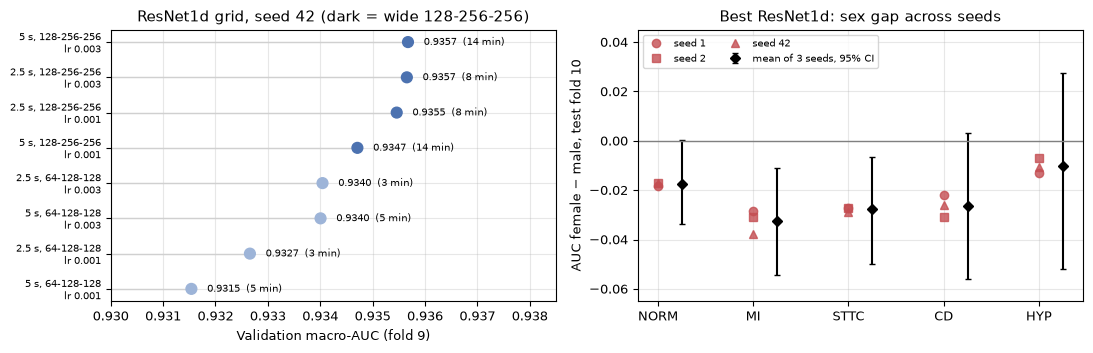

In [7]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
labels = [f"{w:g} s, {c}\nlr {lr:g}" for w, c, lr in zip(grid.window_s, grid.widths, grid.lr)]
colors = ['#4C72B0' if c == '128-256-256' else '#9DB4D8' for c in grid.widths]
yy = np.arange(len(grid))[::-1]
ax[0].hlines(yy, 0.930, grid['val macro-AUC'], color='#D0D0D0', lw=1)
ax[0].scatter(grid['val macro-AUC'], yy, c=colors, s=60, zorder=3)
for y_, v, t in zip(yy, grid['val macro-AUC'], grid.train_min):
    ax[0].text(v + 0.0003, y_, f'{v:.4f}  ({t:.0f} min)', va='center', fontsize=7)
ax[0].set_yticks(yy, labels, fontsize=7)
ax[0].set(xlim=(0.930, 0.9385), xlabel='Validation macro-AUC (fold 9)',
          title='ResNet1d grid, seed 42 (dark = wide 128-256-256)')

x = np.arange(len(SUPERCLASSES))
for rid, mk in zip(SEED_RUNS, ('o', 's', '^')):
    s = RUNS[rid]['s_test']
    g = auc_per_class(y_te[sex_te == 'female'], s[sex_te == 'female']) \
        - auc_per_class(y_te[sex_te == 'male'], s[sex_te == 'male'])
    ax[1].plot(x, g, marker=mk, ls='none', ms=6, color='#C44E52', alpha=0.8,
               label=f"seed {RUNS[rid]['config']['seed']}")
gp = gap_best.loc[SUPERCLASSES]
ax[1].errorbar(x + 0.25, gp['female - male'], yerr=[gp['female - male'] - gp['CI low'],
                                                     gp['CI high'] - gp['female - male']],
               fmt='D', color='black', ms=5, capsize=2, label='mean of 3 seeds, 95% CI')
ax[1].axhline(0, color='gray', lw=1)
ax[1].set_xticks(x, SUPERCLASSES)
ax[1].set(ylabel='AUC female − male, test fold 10', title='Best ResNet1d: sex gap across seeds')
ax[1].legend(fontsize=7, loc='upper left', ncol=2)
ax[1].set_ylim(-0.065, 0.045)
plt.tight_layout()
plt.savefig(FIG_DIR + 'w7_grid_seeds.png', dpi=150)
plt.show()

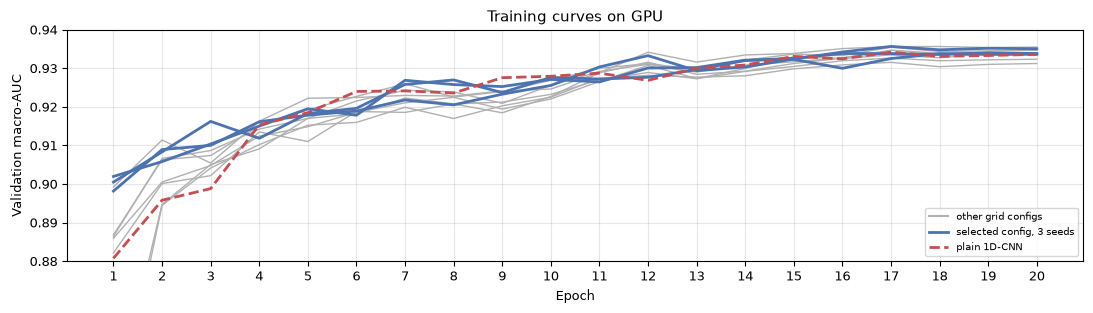

In [8]:
fig, ax = plt.subplots(figsize=(11, 3.2))
for rid, r in RUNS.items():
    c = r['config']
    if c['model'] == 'resnet1d' and rid not in SEED_RUNS:
        h = pd.DataFrame(r['history'])
        ax.plot(h.epoch, h.val_macro_auc, color='#B0B0B0', lw=1)
for rid in SEED_RUNS:
    h = pd.DataFrame(RUNS[rid]['history'])
    ax.plot(h.epoch, h.val_macro_auc, color='#4C72B0', lw=2)
h = pd.DataFrame(RUNS[CNN]['history'])
ax.plot(h.epoch, h.val_macro_auc, color='#C44E52', lw=2, ls='--')
ax.plot([], [], color='#B0B0B0', label='other grid configs')
ax.plot([], [], color='#4C72B0', lw=2, label='selected config, 3 seeds')
ax.plot([], [], color='#C44E52', lw=2, ls='--', label='plain 1D-CNN')
ax.set_xticks(range(1, 21))
ax.set(ylim=(0.88, 0.94), xlabel='Epoch', ylabel='Validation macro-AUC', title='Training curves on GPU')
ax.legend(fontsize=7, loc='lower right')
plt.tight_layout()
plt.savefig(FIG_DIR + 'w7_curves.png', dpi=150)
plt.show()

## Выводы недели 7

**Перенос на GPU корректен.** ResNet1d с настройками недели 5 на Tesla T4: test macro-AUC 0.9295 против
0.9297 на CPU (−0.0001 [−0.0016; +0.0012]), корреляция предсказаний 0.990. Обучение — 3.2 минуты
вместо 39, то есть в 12 раз быстрее. Дальше все глубокие модели сравниваются только между GPU-запусками.

**Простой 1D-CNN достаточно.** Сеть без остаточных связей (457 тыс. параметров) не хуже ResNet1d:
test macro-AUC 0.932 против 0.930 (+0.0024 [−0.0007; +0.0051], незначимо), обучение 0.7 минуты. На
глубине в 3–4 блока остаточные связи не дают выигрыша.

**Подбор гиперпараметров на тесте ничего не дал.** Вся сетка из 8 конфигураций уложилась в 0.004
val macro-AUC (0.9315–0.9357). Шире сеть — в среднем +0.0023, lr 3e-3 — +0.0013, окно 5 с — −0.0005.
Выбранная конфигурация (окно 5 с, 128-256-256, lr 3e-3) в 4 раза больше и в 4 раза медленнее базовой, но
на тесте даёт те же 0.930 [0.923; 0.936] (среднее по 3 seed; +0.0002 [−0.0015; +0.0019] к базовой).
Прирост на фолде 9 — оптимизм выбора, а не реальное улучшение: ResNet1d на PTB-XL упирается в
потолок ≈ 0.93. Ёмкость модели не является ограничением.

**Разрыв по полу — не шум обучения.** На трёх seed разброс test macro-AUC — 0.0013, разброс разрыва
по MI — 0.005, при самом разрыве −0.032. Усреднённый по seed разрыв значим: macro −0.023 [−0.037; −0.009],
MI −0.032 [−0.055; −0.011], STTC −0.028 [−0.050; −0.007]. При общем пороге скрининга чувствительность
к MI у женщин 0.858 против 0.921 у мужчин. Открытый вопрос недели 5 закрыт: разрыв воспроизводится при
любом seed.

## План на неделю 8

Гибридные модели CNN-LSTM и CNN-Transformer с attention-pooling уже обучены на Colab (по 3 seed):
сравнение с ResNet1d и простой CNN на тесте, разрыв по полу у каждой архитектуры, стоимость обучения.